# Statistical Study - Artificial Intelligence Adoption in Higher Education

## Study Overview
This notebook presents the preparation and statistical analysis of survey responses collected from students about the adoption of artificial intelligence technologies in higher education.

The objective is to transform raw responses into analysis-ready data, describe the observed trends, and explore selected relationships between variables.

**Analysis workflow:**
1. Load and inspect the dataset.
2. Check data quality and clean the variables.
3. Prepare the Likert-scale responses.
4. Calculate scores for each study dimension.
5. Perform descriptive and statistical analyses.
6. Present and export the results.

> **Note:** Results depend on the source dataset. Missing values are not replaced with arbitrary values, and potential data-quality issues are flagged for review.

## 1. Importing the Required Libraries

We use:
- `pandas` and `numpy` to manipulate and prepare the data;
- `matplotlib` and `seaborn` to create clear visualizations;
- `scipy` to perform statistical tests.

Only the libraries needed for this analysis are imported.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Loading and Exploring the Dataset

We first load the Excel file and inspect its structure before making any changes.

This step helps us identify:
- the number of respondents and variables;
- column names and data types;
- a sample of records to understand how responses are stored.

The `datasheet.xlsx` file must be located in the same folder as this notebook.

In [2]:
data = pd.read_excel("datasheet.xlsx")

print(f"Number of respondents: {data.shape[0]}")
print(f"Number of variables: {data.shape[1]}")

data.head()

Number of respondents: 51
Number of variables: 27


,Horodateur,Adresse e-mail,Genre,Age,Filière,Année d'étude,Adoption de la technologie [Je pense que l'adoption des nouvelles technologies et vidéoconférence était une solution pratique pour continuer les enseignements pendant la pandémie],Adoption de la technologie [Je pense que l'utilisation des plateformes est très pratique par rapport à l'apprentissage traditionnelle],Intention d'utilisation [J'ai l'intention d'utiliser ces technologies uniquement pour mes études],Intention d'utilisation [Je souhaite utiliser ces plateformes pour les études à l'étranger],Intention d'utilisation [Je désire passer des entretiens d'embauche en vidéoconférence],Intention d'utilisation [J'ai l'intention de faire des réunions plus souvent sur les plateformes de vidéoconférence],Facilité d'utilisation [Je trouve que l'utilisation de la technologie vidéoconférence / plateformes est facile],Facilité d'utilisation [Je trouve la facilité de naviguer entre les différents plateformes],Facilité d'utilisation [Les outils de vidéoconférence facilitent les discussions en temps réel entre les étudiants et les enseignants],Facilité d'utilisation [Je peux rendre mes devoirs facilement sur ces plateformes.],Facilité d'utilisation [Je pense pouvoir apprendre facilement à utiliser ces technologies .],Facilité d'utilisation [Je peux gérer facilement mon emploi du temps],L' Utilité de cette technologie [Je trouve ces technologies utiles car je peux suivre les cours à l'étranger / études à travers cours à distance],L' Utilité de cette technologie [Je peux utiliser les vidéoconférences pour travailler sur les projets d'une manière plus flexible],L' Utilité de cette technologie [Je peux améliorer mes compétences plus rapidement],"L' Utilité de cette technologie [En utilisant les vidéoconférences , je peux regarder les cours vidéo à n'importe quelle moments.]",L' Attitude [L'utilisation des nouvelles technologies a une bonne influence sur l'enseignement supérieure .],L' Attitude [Je préfère passer des tests à distance],L' Aspect sociale [L'utilisation des nouvelles technologies a un impact négative sur ma vie sociale .],L' Aspect sociale [Les nouvelles technologies me permettent de faire de nouvelles connaissances et d'avoir des interactions avec les gens ],"L' Aspect sociale [Parfois, cela peut conduire à une diminution du temps passé en face à face, à une réduction de l'interaction physique et à un sentiment de distance émotionnelle]"
0,2023-05-13 12:40:31.279,oualid.el-ouardi@uit.ac.ma,Homme,20,Génie Informatique,1 ère année CI,Tout à fait d'accord,D'accord,Pas d'accord,Pas d'accord,D'accord,D'accord,Tout à fait d'accord,Tout à fait d'accord,D'accord,Tout à fait d'accord,D'accord,Tout à fait d'accord,D'accord,Tout à fait d'accord,D'accord,Tout à fait d'accord,D'accord,Tout à fait d'accord,Pas d'accord,Pas d'accord,Neutre
1,2023-05-13 13:04:45.538,nassim.elaouad@uit.ac.ma,Homme,21,Génie Informatique,1 ère année CI,Tout à fait d'accord,D'accord,Pas d'accord,D'accord,Tout à fait d'accord,D'accord,Tout à fait d'accord,Tout à fait d'accord,D'accord,D'accord,D'accord,D'accord,Tout à fait d'accord,D'accord,D'accord,Tout à fait d'accord,D'accord,Tout à fait d'accord,D'accord,D'accord,Tout à fait d'accord
2,2023-05-13 13:14:56.822,hamza.elgourchi@uit.ac.ma,Homme,22,Génie Informatique,1 ère année CI,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord,D'accord
3,2023-05-13 13:18:48.361,maryam.chagour@uit.ac.ma,Femme,20,Génie Informatique,1 ère année CI,Tout à fait d'accord,Neutre,Pas d'accord,D'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,Tout à fait d'accord,D'accord,Pas d'accord,D'accord,D'accord
4,2023-05-13 13:20:05.466,wiam.drissielhaou

## 3. Assessing Data Quality

Before cleaning the dataset, we check for missing values and duplicate records.

**Why is this necessary?**
- Missing values may reduce the number of observations available for an analysis.
- Duplicate records may count the same response more than once and distort the results.

Only fully duplicated rows are removed. Missing values are identified first and are not automatically replaced.

In [3]:
# Remove a possible index column exported from Excel
# Remove it only when its name clearly indicates that it is an index.
first_col = str(data.columns[0]).strip().lower()
if first_col.startswith("unnamed") or first_col in ["index", "id.1"]:
    data = data.drop(columns=data.columns[0])

# Remove fully duplicated rows
duplicate_count = data.duplicated().sum()
data = data.drop_duplicates().copy()

print(f"Duplicate rows removed: {duplicate_count}")
print(f"Dataset shape after removal: {data.shape}")

missing_summary = (
    data.isna().sum()
        .to_frame("Missing values")
        .assign(**{"Percentage (%)": lambda x: (x["Missing values"] / len(data) * 100).round(1)})
)
missing_summary.sort_values("Missing values", ascending=False)

Duplicate rows removed: 0
Dataset shape after removal: (51, 27)


,Missing values,Percentage (%)
Horodateur,0,0.0
Facilité d'utilisation [Les outils de vidéoconférence facilitent les discussions en temps réel entre les étudiants et les enseignants],0,0.0
L' Aspect sociale [Les nouvelles technologies me permettent de faire de nouvelles connaissances et d'avoir des interactions avec les gens ],0,0.0
L' Aspect sociale [L'utilisation des nouvelles technologies a un impact négative sur ma vie sociale .],0,0.0
L' Attitude [Je préfère passer des tests à distance],0,0.0
L' Attitude [L'utilisation des nouvelles technologies a une bonne influence sur l'enseignement supérieure .],0,0.0
"L' Utilité de cette technologie [En utilisant les vidéoconférences , je peux regarder les cours vidéo à n'importe quelle moments.]",0,0.0
L' Utilité de cette technologie [Je peux améliorer mes compétences plus rapidement],0,0.0
L' Utilité de cette technologie [Je peux utiliser les vidéoconférences pour travailler sur les projets d'une manière plus flexible],0,0.0
L' Utilité de cette technologie [Je trouve ces technologies utiles car je peux suivre les cours à l'étranger / études à travers cours à distance],0,0.0


## 4. Preparing and Validating Variables

Demographic variables are treated as categorical variables. Age is converted to a numeric format so that descriptive statistics can be calculated.

This step prevents values stored as text (for example, an age entered as a string) from interfering with calculations. Values that cannot be converted are treated as missing and counted for review.

In [4]:
# Check that all expected variables are present
required_columns = ["Genre", "Filière", "Année d'étude", "Age"]
missing_columns = [col for col in required_columns if col not in data.columns]

if missing_columns:
    raise ValueError(f"Expected columns are missing from the file: {missing_columns}")

# Remove leading and trailing spaces from text responses
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

# Convert age to numeric; invalid values become NaN
data["Age"] = pd.to_numeric(data["Age"], errors="coerce")

# Treat respondent profile variables as categorical
for col in ["Genre", "Filière", "Année d'étude"]:
    data[col] = data[col].astype("category")

print("Missing or non-numeric age values:", data["Age"].isna().sum())
data[["Genre", "Filière", "Année d'étude", "Age"]].head()

Missing or non-numeric age values: 0


,Genre,Filière,Année d'étude,Age
0,Homme,Génie Informatique,1 ère année CI,20
1,Homme,Génie Informatique,1 ère année CI,21
2,Homme,Génie Informatique,1 ère année CI,22
3,Femme,Génie Informatique,1 ère année CI,20
4,Femme,Génie Informatique,1 ère année CI,20


## 5. Renaming Survey Questions and Encoding the Likert Scale

Survey questions are assigned short identifiers (A1, I1, F1, etc.) to make them easier to handle in the analysis.

The identifiers are grouped by study dimension:
- A: Adoption
- I: Intention to use
- F: Ease of use
- U: Perceived usefulness
- At: Attitude
- As: Social influence

Responses are then converted to an ordered scale from 1 to 5. Missing responses remain missing (`NaN`); they are not coded as 0 because 0 is not part of the response scale.

In [5]:
likert_labels = [
    "A1", "A2",
    "I1", "I2", "I3", "I4",
    "F1", "F2", "F3", "F4", "F5", "F6",
    "U1", "U2", "U3", "U4",
    "At1", "At2",
    "As1", "As2", "As3"
]

# In the source file, Likert questions start in the sixth column.
start_position = 5
end_position = start_position + len(likert_labels)

if len(data.columns) < end_position:
    raise ValueError("The file does not contain enough columns for the Likert questions.")

original_question_columns = data.columns[start_position:end_position].tolist()

if len(original_question_columns) != len(likert_labels):
    raise ValueError("The number of detected questions does not match the number of identifiers.")

data = data.rename(columns=dict(zip(original_question_columns, likert_labels)))

likert_mapping = {
    "Pas du tout d'accord": 1,
    "Pas d'accord": 2,
    "Neutre": 3,
    "D'accord": 4,
    "Tout à fait d'accord": 5
}

# Normalize labels to avoid differences in spacing or capitalization
for col in likert_labels:
    answers = data[col].astype("string").str.strip()
    data[col] = answers.map(likert_mapping)

# Identify unrecognized responses (excluding missing values)
unrecognized = {}
for col in likert_labels:
    original_values = data[col].isna().sum()
    unrecognized[col] = original_values

print("Missing or unrecognized responses after encoding:")
pd.Series(unrecognized, name="Nombre").to_frame()

Missing or unrecognized responses after encoding:


,Nombre
A1,51
A2,0
I1,0
I2,0
I3,0
I4,0
F1,0
F2,0
F3,0
F4,0


## 6. Checking the Age Variable

We examine the age distribution and identify potential outliers using the interquartile range (IQR) method.

An outlier is not necessarily an error. It is therefore **flagged for review**, rather than automatically replaced with the mean. Such replacement would artificially modify the data and could reduce the observed variability.

Impossible or clearly incorrect values should be checked against the original questionnaire before being corrected.

In [6]:
age_summary = data["Age"].describe()
print("Age descriptive statistics:")
age_summary

Age descriptive statistics:


count    51.000000
mean     20.647059
std       0.687707
min      19.000000
25%      20.000000
50%      21.000000
75%      21.000000
max      22.000000
Name: Age, dtype: float64

IQR bounds: [18.5 ; 22.5]
Potential outliers detected: 0


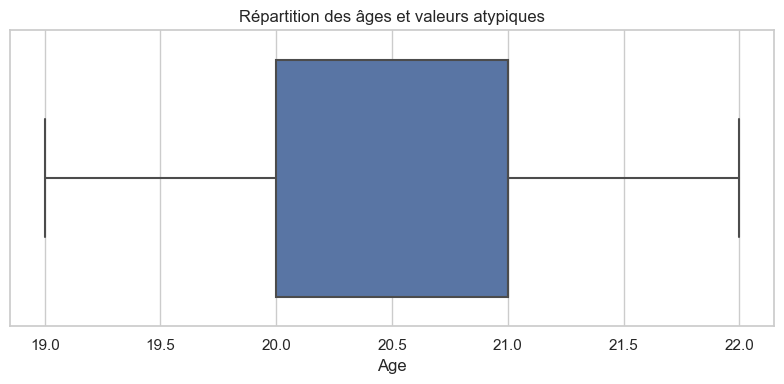

In [7]:
q1 = data["Age"].quantile(0.25)
q3 = data["Age"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

age_outliers = data["Age"].notna() & (
    (data["Age"] < lower_bound) | (data["Age"] > upper_bound)
)

print(f"IQR bounds: [{lower_bound:.1f} ; {upper_bound:.1f}]")
print(f"Potential outliers detected: {age_outliers.sum()}")

plt.figure(figsize=(8, 4))
sns.boxplot(x=data["Age"])
plt.title("Répartition des âges et valeurs atypiques")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

## 7. Descriptive Analysis of Respondent Profiles

This section describes the composition of the sample. Counts and percentages show which respondent profiles are represented.

These results describe only the people who completed the questionnaire. They should not be generalized to all students without considering the sampling method.

In [8]:
profile_columns = ["Genre", "Filière", "Année d'étude"]

for col in profile_columns:
    print(f"Distribution — {col}")
    distribution = data[col].value_counts(dropna=False).to_frame("Count")
    distribution["Percentage (%)"] = (distribution["Count"] / len(data) * 100).round(1)
    print(distribution)
    print()

Distribution — Genre
       Count  Percentage (%)
Genre                       
Femme     30            58.8
Homme     21            41.2

Distribution — Filière
                                           Count  Percentage (%)
Filière                                                         
Génie Informatique                            27            52.9
Génie Industrielle                            13            25.5
Génie Mécatronique                             4             7.8
Génie Réseau Système et Télécommunication      4             7.8
Génie Electrique                               3             5.9

Distribution — Année d'étude


KeyError: "Année d'étude"

## 8. Creating Scores for Each Study Dimension

Several questions are designed to measure the same dimension. For each respondent, we calculate the mean of the available answers within each group of questions.

This approach keeps the original 1-to-5 scale and makes it easier to compare dimensions. A score remains missing when no answer is available for that dimension.

In [9]:
dimensions = {
    "Adoption_score": ["A1", "A2"],
    "Intention_score": ["I1", "I2", "I3", "I4"],
    "Facilite_score": ["F1", "F2", "F3", "F4", "F5", "F6"],
    "Utilite_score": ["U1", "U2", "U3", "U4"],
    "Attitude_score": ["At1", "At2"],
    "Social_score": ["As1", "As2", "As3"]
}

for score_name, items in dimensions.items():
    data[score_name] = data[items].mean(axis=1)

score_columns = list(dimensions.keys())
data[score_columns].describe().round(2)

,Adoption_score,Intention_score,Facilite_score,Utilite_score,Attitude_score,Social_score
count,51.00,51.00,51.00,51.00,51.00,51.00
mean,4.27,3.22,4.07,3.95,4.11,3.06
std,1.00,0.75,0.74,0.88,0.92,0.76
min,1.00,1.50,1.50,1.25,1.50,1.00
25%,4.00,2.75,3.75,3.75,4.00,2.67
50%,4.00,3.25,4.00,4.00,4.50,3.00
75%,5.00,3.75,4.58,4.50,4.75,3.67
max,5.00,4.75,5.00,5.00,5.00,4.33


## 9. Internal Consistency of the Dimensions (Cronbach's Alpha)

Cronbach's alpha measures the internal consistency of a group of questions intended to measure the same dimension.

It is calculated separately for each dimension rather than across all questions, because the questions do not all measure the same concept.

Interpret the result with caution, especially for dimensions containing only two questions. A high alpha value does not, by itself, prove that a scale is valid.

In [10]:
def cronbach_alpha(items):
    # Écarter les répondants sans aucune réponse à cette dimension
    items = items.dropna(how="all")

    # L'alpha n'est pas calculable avec moins de deux questions
    if items.shape[1] < 2:
        return np.nan

    # Utiliser les lignes complètes pour assurer un calcul cohérent
    items = items.dropna()

    if len(items) < 2:
        return np.nan

    item_variances = items.var(axis=0, ddof=1)
    total_score_variance = items.sum(axis=1).var(ddof=1)

    if total_score_variance == 0:
        return np.nan

    number_of_items = items.shape[1]
    return (number_of_items / (number_of_items - 1)) * (
        1 - item_variances.sum() / total_score_variance
    )

reliability = []
for dimension, items in dimensions.items():
    alpha = cronbach_alpha(data[items])
    reliability.append({
        "Dimension": dimension.replace("_score", ""),
        "Number of questions": len(items),
        "Cronbach's alpha": round(alpha, 3) if pd.notna(alpha) else np.nan
    })

pd.DataFrame(reliability)

,Dimension,Number of questions,Cronbach's alpha
0,Adoption,2,NaN
1,Intention,4,0.548
2,Facilite,6,0.802
3,Utilite,4,0.811
4,Attitude,2,0.770
5,Social,3,0.157


## 10. Key Study Indicators (KPIs)

The rates below represent the percentage of respondents whose average score is at least 4 out of 5.

A threshold of 4 is used here to represent a positive tendency (answers generally corresponding to “Agree” or “Strongly agree”). This is an analytical choice that should be clearly stated and applied consistently.

In [11]:
kpi_definitions = {
    "Adoption rate": "Adoption_score",
    "Strong intention to use": "Intention_score",
    "Positive attitude": "Attitude_score"
}

kpi_results = []
for label, score_col in kpi_definitions.items():
    valid_scores = data[score_col].dropna()
    rate = (valid_scores >= 4).mean() * 100 if len(valid_scores) else np.nan

    kpi_results.append({
        "Indicator": label,
        "Respondents included": len(valid_scores),
        "Rate (%)": round(rate, 1) if pd.notna(rate) else np.nan
    })

kpi_table = pd.DataFrame(kpi_results)
kpi_table

,Indicator,Respondents included,Rate (%)
0,Adoption rate,51,90.2
1,Strong intention to use,51,21.6
2,Positive attitude,51,76.5


## 11. Visualizing the Results

The charts help identify the main patterns in the data:
- the age distribution describes the sample profile;
- mean scores make it possible to compare the study dimensions;
- the KPI chart summarizes the main rates.

These charts are descriptive and do not, on their own, demonstrate cause-and-effect relationships.

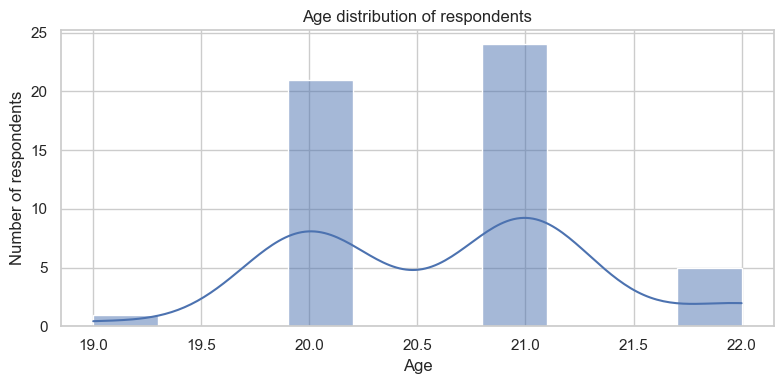

In [12]:
# Age distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="Age", bins=10, kde=True)
plt.title("Age distribution of respondents")
plt.xlabel("Age")
plt.ylabel("Number of respondents")
plt.tight_layout()
plt.show()

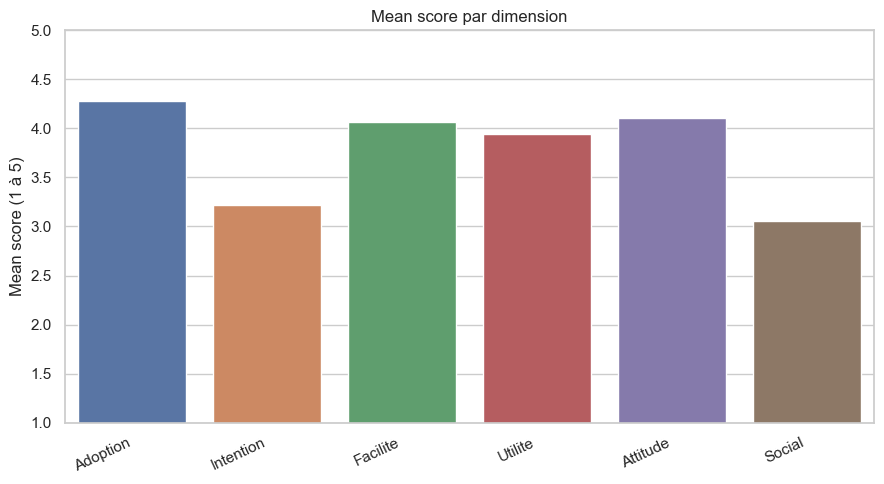

In [13]:
# Compare mean scores across dimensions
dimension_summary = (
    data[score_columns]
    .mean()
    .rename_axis("Dimension")
    .reset_index(name="Mean score")
)
dimension_summary["Dimension"] = dimension_summary["Dimension"].str.replace("_score", "", regex=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=dimension_summary, x="Dimension", y="Mean score")
plt.ylim(1, 5)
plt.title("Mean score par dimension")
plt.xlabel("")
plt.ylabel("Mean score (1 à 5)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

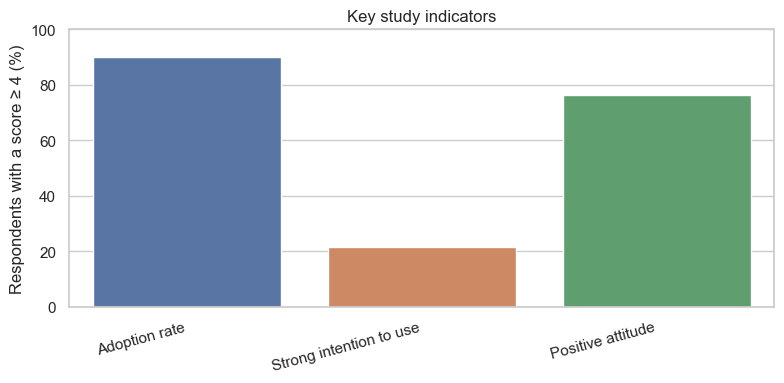

In [14]:
# Summary of key indicators
plt.figure(figsize=(8, 4))
sns.barplot(data=kpi_table, x="Indicator", y="Rate (%)")
plt.ylim(0, 100)
plt.title("Key study indicators")
plt.ylabel("Respondents with a score ≥ 4 (%)")
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 12. Exploring Relationships: Chi-Square Test of Independence

The Chi-square test of independence is used to assess whether two categorical variables are statistically associated.

**Hypotheses:**
- **H0:** The two variables are independent.
- **H1:** The two variables are associated.

The test statistic, degrees of freedom, and p-value are reported. At a 5% significance level:
- if the p-value is below 0.05, we reject H0;
- otherwise, there is insufficient evidence to reject H0.

The test requires sufficiently large expected frequencies. If too many expected counts are below 5, the results should be interpreted with caution. Relationships should be selected based on the research questions rather than by testing every possible combination.

In [15]:
def chi2_independence(dataframe, variable_1, variable_2):
    contingency_table = pd.crosstab(
        dataframe[variable_1],
        dataframe[variable_2]
    )

    if contingency_table.shape[0] < 2 or contingency_table.shape[1] < 2:
        print("Test cannot be performed: each variable must contain at least two categories.")
        return None

    chi2, p_value, degrees_of_freedom, expected = chi2_contingency(contingency_table)

    print(f"Variables analyzed: {variable_1} et {variable_2}")
    print(f"Chi-square statistic: {chi2:.3f}")
    print(f"Degrees of freedom: {degrees_of_freedom}")
    print(f"P-value: {p_value:.4f}")
    print(f"Count théorique minimum : {expected.min():.2f}")

    if (expected < 5).any():
        print("Warning: some expected frequencies are below 5.")

    if p_value < 0.05:
        print("Conclusion: statistically significant association at the 5% significance level.")
    else:
        print("Conclusion: no statistically significant association detected at the 5% significance level.")

    return contingency_table

# Examples of relationships explored in the study
chi2_independence(data, "As2", "F1")
chi2_independence(data, "F5", "U3")
chi2_independence(data, "U2", "At1")

Variables analyzed: As2 et F1
Chi-square statistic: 21.500
Degrees of freedom: 16
P-value: 0.1601
Count théorique minimum : 0.04
Conclusion: no statistically significant association detected at the 5% significance level.
Variables analyzed: F5 et U3
Chi-square statistic: 31.720
Degrees of freedom: 16
P-value: 0.0109
Count théorique minimum : 0.02
Conclusion: statistically significant association at the 5% significance level.
Variables analyzed: U2 et At1
Chi-square statistic: 64.241
Degrees of freedom: 16
P-value: 0.0000
Count théorique minimum : 0.08
Conclusion: statistically significant association at the 5% significance level.


At1,1,2,3,4,5
U2,,,,,
1,1,1,0,0,0
2,1,1,0,0,0
3,0,0,1,2,0
4,0,0,2,9,15
5,0,0,0,2,16


## 13. Exporting the Prepared Dataset

We export the dataset after completing the preparation steps and creating the dimension scores.

The resulting file can be used in Power BI to build dashboards. Before sharing it, make sure it contains no personal data or confidential information.

In [16]:
output_file = "prepared_data_for_powerbi.csv"
data.to_csv(output_file, index=False, encoding="utf-8-sig")

print(f"Exported file: {output_file}")
print(f"Exported dataset shape: {data.shape[0]} lignes et {data.shape[1]} colonnes")

Exported file: prepared_data_for_powerbi.csv
Exported dataset shape: 51 lignes et 33 colonnes


## 14. Conclusion

This notebook follows a statistical analysis workflow, from preparing survey responses to interpreting indicators.

The analyses describe the sample, compare dimensions related to artificial intelligence adoption, and examine selected relationships between variables.

Final conclusions should be written after running the notebook and reviewing the results. They should also take into account the limitations of the sample, questionnaire, and any missing responses.